# RHE (Receding Horizon Estimator) Qualitative Tests

This notebook contains qualitative tests and visualizations for the RecedingHorizonEstimator class,
including trajectory comparisons, parameter estimation analysis, and cost function behavior.

## Setup and Imports

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
import sys

sys.path.insert(
    0, "/home/lmertens/git-repos/master-thesis-lmertens/data_labeling_pipeline/src"
)
from data_labeling_pipeline.rhe import RecedingHorizonEstimator

# Set matplotlib style
plt.style.use("seaborn-v0_8-darkgrid")
plt.rcParams["figure.figsize"] = (14, 10)
plt.rcParams["font.size"] = 10

## Test 1: Dynamics Model Validation

Test the unicycle dynamics model with various inputs and parameters.

In [23]:
# Test 1: Verify dynamics model
rhe = RecedingHorizonEstimator(dt=0.1, N=50)

# Test case 1: Straight line motion (mu=1, nu=1, no heading change)
state = np.array([0.0, 0.0, 0.0])  # Starting at origin, heading East
u = np.array([1.0, 0.0])  # v=1 m/s, omega=0
m = np.array([1.0, 1.0, 0.0])  # mu=1, nu=1, delta_theta=0

next_state = rhe.dynamics(state, u, m)
expected_dx = 1.0 * np.cos(0.0) * 1.0 * 0.1  # mu * cos(theta) * v * dt
expected_dy = 1.0 * np.sin(0.0) * 1.0 * 0.1  # mu * sin(theta) * v * dt

print("=== Test 1: Dynamics Model ===")
print(f"Initial state: {state}")
print(f"Input (v, omega): {u}")
print(f"Parameters (mu, nu, delta_theta): {m}")
print(f"Next state: {next_state}")
print(f"Expected dx: {expected_dx:.4f}, Actual: {next_state[0]:.4f}")
print(f"Expected dy: {expected_dy:.4f}, Actual: {next_state[1]:.4f}")
print(f"Heading change (should be 0): {next_state[2]:.4f}")
print()

=== Test 1: Dynamics Model ===
Initial state: [0. 0. 0.]
Input (v, omega): [1. 0.]
Parameters (mu, nu, delta_theta): [1. 1. 0.]
Next state: [0.1 0.  0. ]
Expected dx: 0.1000, Actual: 0.1000
Expected dy: 0.0000, Actual: 0.0000
Heading change (should be 0): 0.0000



## Test 2: Simulation with Different Parameters

Visualize how different traversability parameters (mu, nu) affect trajectory prediction.

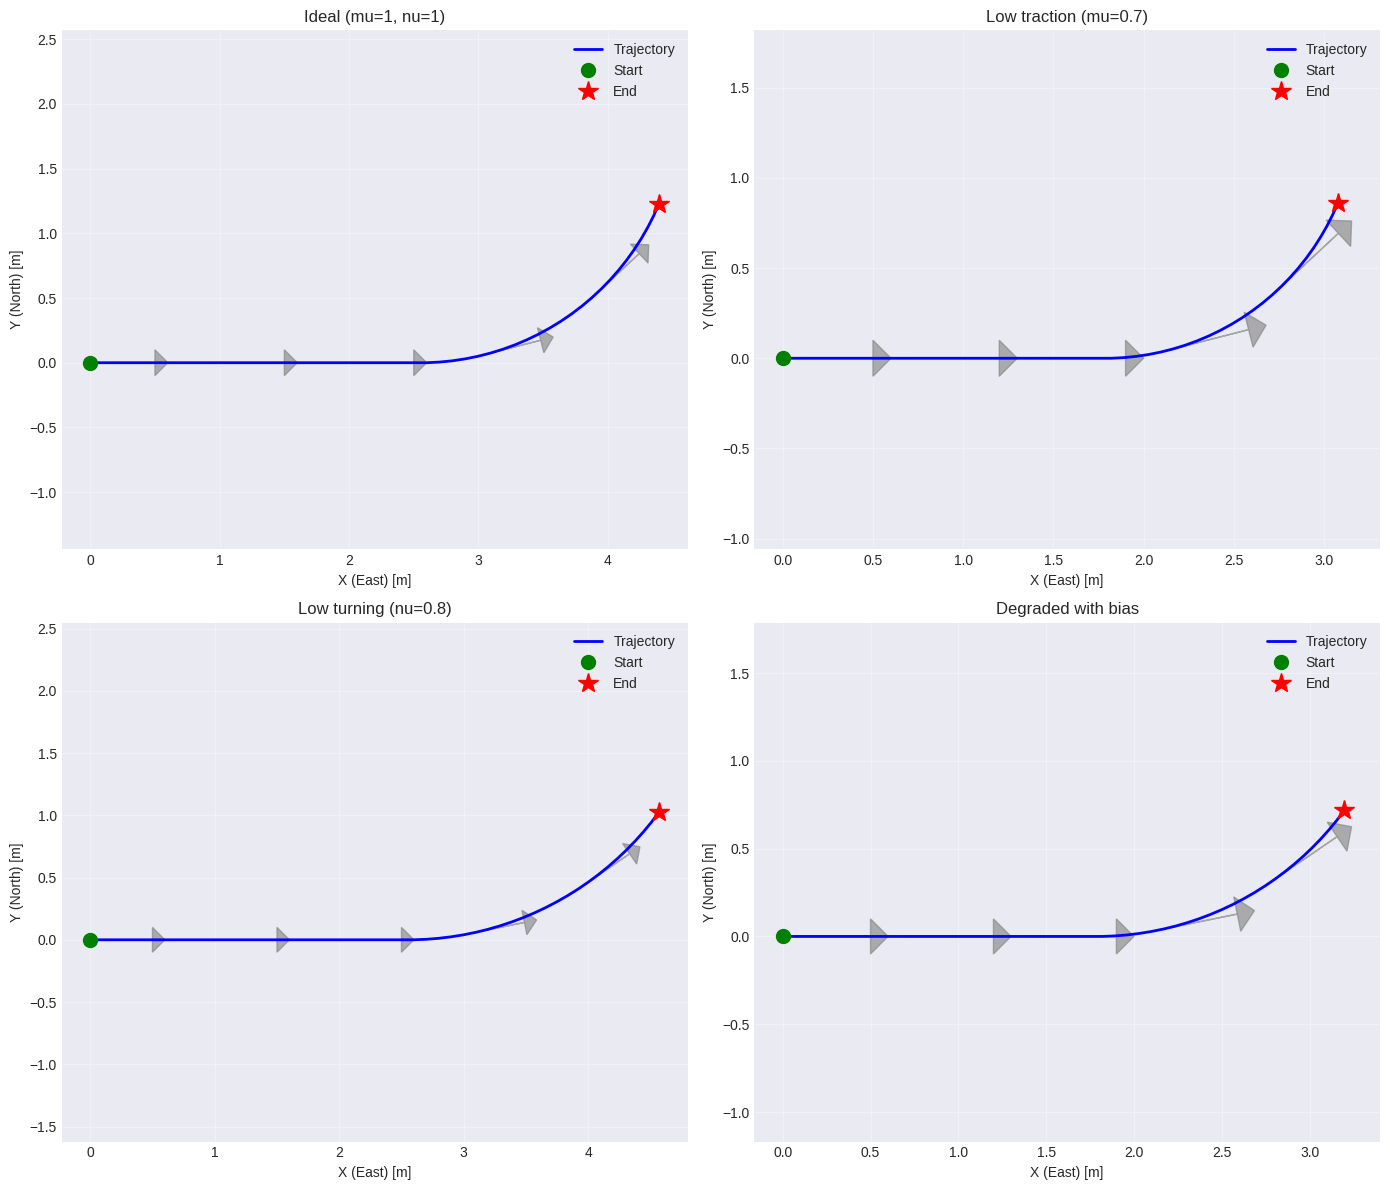

=== Test 2: Simulation Results ===
Ideal (mu=1, nu=1):
  Final position: (4.40, 1.23)
  Distance traveled: 4.56 m
  Final heading: 68.8°

Low traction (mu=0.7):
  Final position: (3.08, 0.86)
  Distance traveled: 3.19 m
  Final heading: 68.8°

Low turning (nu=0.8):
  Final position: (4.57, 1.03)
  Distance traveled: 4.68 m
  Final heading: 55.0°

Degraded with bias:
  Final position: (3.20, 0.72)
  Distance traveled: 3.28 m
  Final heading: 55.0°



In [24]:
# Test 2: Simulate with different parameter values
N = 50
dt = 0.1
rhe = RecedingHorizonEstimator(dt=dt, N=N)

# Generate synthetic input sequence: constant velocity with gradual turn
U = np.zeros((N, 2))
U[:, 0] = 1.0  # constant velocity
U[25:, 1] = 0.5  # start turning at step 25

# Simulate with different parameter combinations
x0 = np.array([0.0, 0.0, 0.0])
params_list = [
    (1.0, 1.0, 0.0, "Ideal (mu=1, nu=1)"),
    (0.7, 1.0, 0.0, "Low traction (mu=0.7)"),
    (1.0, 0.8, 0.0, "Low turning (nu=0.8)"),
    (0.7, 0.8, 0.1, "Degraded with bias"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

trajectories = {}
for idx, (mu, nu, delta_theta, label) in enumerate(params_list):
    m = np.array([mu, nu, delta_theta])
    X = rhe.simulate(x0, U, m)
    trajectories[label] = X

    ax = axes[idx]
    ax.plot(X[:, 0], X[:, 1], "b-", linewidth=2, label="Trajectory")
    ax.plot(X[0, 0], X[0, 1], "go", markersize=10, label="Start")
    ax.plot(X[-1, 0], X[-1, 1], "r*", markersize=15, label="End")

    # Plot heading angles as arrows
    for i in range(0, N, 10):
        arrow_len = 0.5
        dx = arrow_len * np.cos(X[i, 2])
        dy = arrow_len * np.sin(X[i, 2])
        ax.arrow(
            X[i, 0],
            X[i, 1],
            dx,
            dy,
            head_width=0.2,
            head_length=0.1,
            fc="gray",
            ec="gray",
            alpha=0.6,
        )

    ax.set_xlabel("X (East) [m]")
    ax.set_ylabel("Y (North) [m]")
    ax.set_title(f"{label}")
    ax.grid(True, alpha=0.3)
    ax.legend()
    ax.axis("equal")

plt.tight_layout()
plt.savefig("/tmp/rhe_test_trajectories.png", dpi=150, bbox_inches="tight")
plt.show()

print("=== Test 2: Simulation Results ===")
for label, X in trajectories.items():
    distance = np.sqrt((X[-1, 0] - X[0, 0]) ** 2 + (X[-1, 1] - X[0, 1]) ** 2)
    final_heading = X[-1, 2]
    print(f"{label}:")
    print(f"  Final position: ({X[-1, 0]:.2f}, {X[-1, 1]:.2f})")
    print(f"  Distance traveled: {distance:.2f} m")
    print(f"  Final heading: {np.degrees(final_heading):.1f}°")
    print()

## Test 3: State and Parameter Estimation

Test the RHE estimation with synthetic "measured" trajectory and compare predicted vs. actual.

In [25]:
# Test 3: Run the full RHE estimation
np.random.seed(42)

# Generate "true" trajectory with known degraded parameters
N_horizon = 50
N_total = 300  # Total steps for multiple horizon windows
dt = 0.1

# True parameters (simulating degraded conditions)
mu_true = 0.8
nu_true = 0.85
delta_theta_true = 0.05
m_true = np.array([mu_true, nu_true, delta_theta_true])

# Generate realistic input sequence
U_total = np.zeros((N_total, 2))
U_total[:, 0] = 1.0  # constant forward velocity
# Create a serpentine pattern
U_total[0:75, 1] = 0.3
U_total[75:150, 1] = -0.3
U_total[150:225, 1] = 0.3
U_total[225:300, 1] = -0.3

# Simulate true trajectory
rhe_true = RecedingHorizonEstimator(dt=dt, N=N_horizon)
x0_true = np.array([0.0, 0.0, 0.0])
X_true = np.zeros((N_total, 3))
X_true[0] = x0_true

for i in range(N_total - 1):
    X_true[i + 1] = rhe_true.dynamics(X_true[i], U_total[i], m_true)

# Add small measurement noise
measurement_noise = np.random.normal(0, 0.02, X_true.shape)
Z_noisy = X_true + measurement_noise
# Inject measurement bias: measured_theta = true_theta + delta_theta_true
Z_noisy[:, 2] += delta_theta_true

print("=== Test 3: State and Parameter Estimation ===")
print(
    f"True parameters: mu={mu_true}, nu={nu_true}, delta_theta={delta_theta_true:.3f}"
)
print(f"Horizon length: {N_horizon}")
print(f"Total steps: {N_total}")
print()

=== Test 3: State and Parameter Estimation ===
True parameters: mu=0.8, nu=0.85, delta_theta=0.050
Horizon length: 50
Total steps: 300



In [26]:
# Run RHE estimation over multiple windows with 50% overlap
rhe_estimator = RecedingHorizonEstimator(dt=dt, N=N_horizon)

# Only use full-length windows so estimate() always receives shape (N_horizon, 2/3)
step_size = N_horizon // 2
window_starts = list(range(0, N_total - N_horizon + 1, step_size))
num_windows = len(window_starts)

X_predicted = np.zeros((N_total, 3))
m_estimates = np.zeros((num_windows, 3))

for window_idx, window_start in enumerate(window_starts):
    U_window = U_total[window_start : window_start + N_horizon]
    Z_window = Z_noisy[window_start : window_start + N_horizon]

    X_est, m_est = rhe_estimator.estimate(U_window, Z_window)

    # Store the predictions
    end_idx = window_start + N_horizon
    X_predicted[window_start:end_idx] = X_est
    m_estimates[window_idx] = m_est

    if (window_idx + 1) % 4 == 0:
        print(
            f"Window {window_idx + 1}: Estimated parameters: mu={m_est[0]:.3f}, nu={m_est[1]:.3f}, delta_theta={m_est[2]:.4f}"
        )

print(f"\nTotal windows processed: {num_windows}")
print(f"Data coverage: steps 0-{window_starts[-1] + N_horizon} in full windows")

Window 4: Estimated parameters: mu=0.806, nu=0.842, delta_theta=0.0525
Window 8: Estimated parameters: mu=0.806, nu=0.857, delta_theta=0.0497

Total windows processed: 11
Data coverage: steps 0-300 in full windows


## Test 4: Trajectory Comparison - Actual vs. Predicted

Plot the measured trajectory (Z) against the predicted trajectory from RHE.

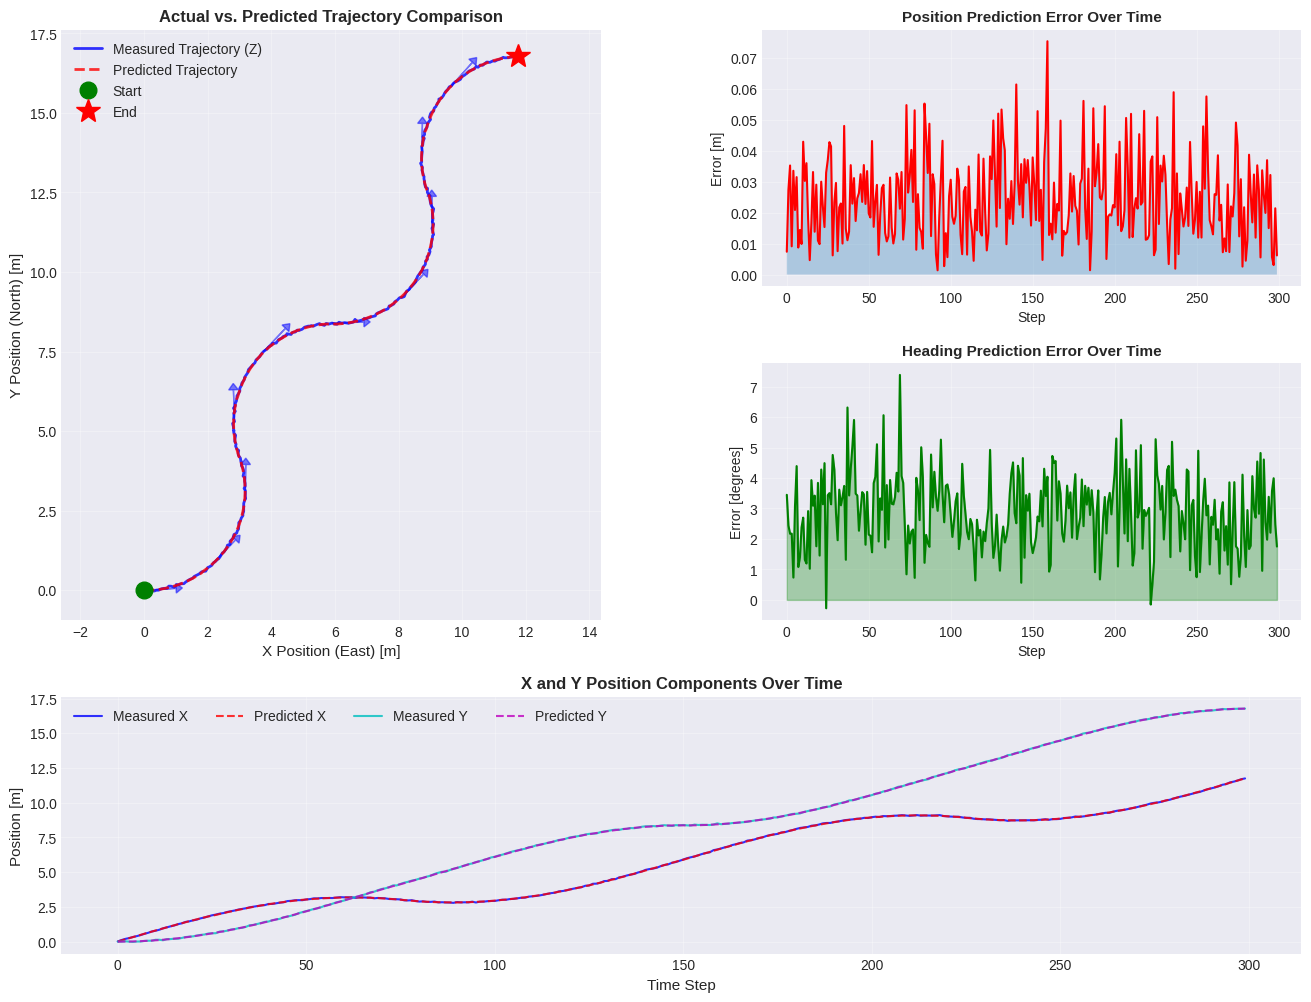

=== Trajectory Comparison Statistics ===
Mean position error: 0.0245 m
Max position error: 0.0755 m
Std dev position error: 0.0135 m
Mean heading error: 2.8853°
Max heading error: 7.3850°


In [27]:
# Plot trajectory comparison
fig = plt.figure(figsize=(16, 12))
gs = GridSpec(3, 2, figure=fig, hspace=0.3, wspace=0.3)

# Main trajectory plot
ax_main = fig.add_subplot(gs[0:2, 0])
ax_main.plot(
    Z_noisy[:, 0],
    Z_noisy[:, 1],
    "b-",
    linewidth=2,
    label="Measured Trajectory (Z)",
    alpha=0.8,
)
ax_main.plot(
    X_predicted[:, 0],
    X_predicted[:, 1],
    "r--",
    linewidth=2,
    label="Predicted Trajectory",
    alpha=0.8,
)
ax_main.plot(Z_noisy[0, 0], Z_noisy[0, 1], "go", markersize=12, label="Start", zorder=5)
ax_main.plot(Z_noisy[-1, 0], Z_noisy[-1, 1], "r*", markersize=18, label="End", zorder=5)

# Plot heading vectors every 30 steps
for i in range(0, N_total, 30):
    arrow_len = 1.0
    dx_measured = arrow_len * np.cos(Z_noisy[i, 2])
    dy_measured = arrow_len * np.sin(Z_noisy[i, 2])
    ax_main.arrow(
        Z_noisy[i, 0],
        Z_noisy[i, 1],
        dx_measured,
        dy_measured,
        head_width=0.3,
        head_length=0.2,
        fc="blue",
        ec="blue",
        alpha=0.5,
    )

ax_main.set_xlabel("X Position (East) [m]", fontsize=11)
ax_main.set_ylabel("Y Position (North) [m]", fontsize=11)
ax_main.set_title(
    "Actual vs. Predicted Trajectory Comparison", fontsize=12, fontweight="bold"
)
ax_main.legend(fontsize=10, loc="best")
ax_main.grid(True, alpha=0.3)
ax_main.axis("equal")

# Trajectory error over time
ax_error = fig.add_subplot(gs[0, 1])
position_error = np.sqrt(
    (X_predicted[:, 0] - Z_noisy[:, 0]) ** 2 + (X_predicted[:, 1] - Z_noisy[:, 1]) ** 2
)
ax_error.plot(position_error, "r-", linewidth=1.5, label="Position Error")
ax_error.fill_between(range(len(position_error)), position_error, alpha=0.3)
ax_error.set_xlabel("Step", fontsize=10)
ax_error.set_ylabel("Error [m]", fontsize=10)
ax_error.set_title(
    "Position Prediction Error Over Time", fontsize=11, fontweight="bold"
)
ax_error.grid(True, alpha=0.3)

# Heading comparison
ax_heading = fig.add_subplot(gs[1, 1])
heading_error = np.degrees(
    (Z_noisy[:, 2] - X_predicted[:, 2] + np.pi) % (2 * np.pi) - np.pi
)
ax_heading.plot(heading_error, "g-", linewidth=1.5, label="Heading Error")
ax_heading.fill_between(
    range(len(heading_error)), heading_error, alpha=0.3, color="green"
)
ax_heading.set_xlabel("Step", fontsize=10)
ax_heading.set_ylabel("Error [degrees]", fontsize=10)
ax_heading.set_title(
    "Heading Prediction Error Over Time", fontsize=11, fontweight="bold"
)
ax_heading.grid(True, alpha=0.3)

# X and Y positions
ax_xy = fig.add_subplot(gs[2, :])
time_steps = np.arange(N_total)
ax_xy.plot(
    time_steps, Z_noisy[:, 0], "b-", linewidth=1.5, label="Measured X", alpha=0.8
)
ax_xy.plot(
    time_steps, X_predicted[:, 0], "r--", linewidth=1.5, label="Predicted X", alpha=0.8
)
ax_xy.plot(
    time_steps, Z_noisy[:, 1], "c-", linewidth=1.5, label="Measured Y", alpha=0.8
)
ax_xy.plot(
    time_steps, X_predicted[:, 1], "m--", linewidth=1.5, label="Predicted Y", alpha=0.8
)
ax_xy.set_xlabel("Time Step", fontsize=11)
ax_xy.set_ylabel("Position [m]", fontsize=11)
ax_xy.set_title("X and Y Position Components Over Time", fontsize=12, fontweight="bold")
ax_xy.legend(fontsize=10, ncol=4)
ax_xy.grid(True, alpha=0.3)

plt.savefig("/tmp/rhe_trajectory_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# Print statistics
print("=== Trajectory Comparison Statistics ===")
print(f"Mean position error: {np.mean(position_error):.4f} m")
print(f"Max position error: {np.max(position_error):.4f} m")
print(f"Std dev position error: {np.std(position_error):.4f} m")
print(f"Mean heading error: {np.mean(np.abs(heading_error)):.4f}°")
print(f"Max heading error: {np.max(np.abs(heading_error)):.4f}°")

## Test 4b: Time-Varying Parameter Tracking

Track parameter estimates over a longer horizon while the true traversability parameters change over time.

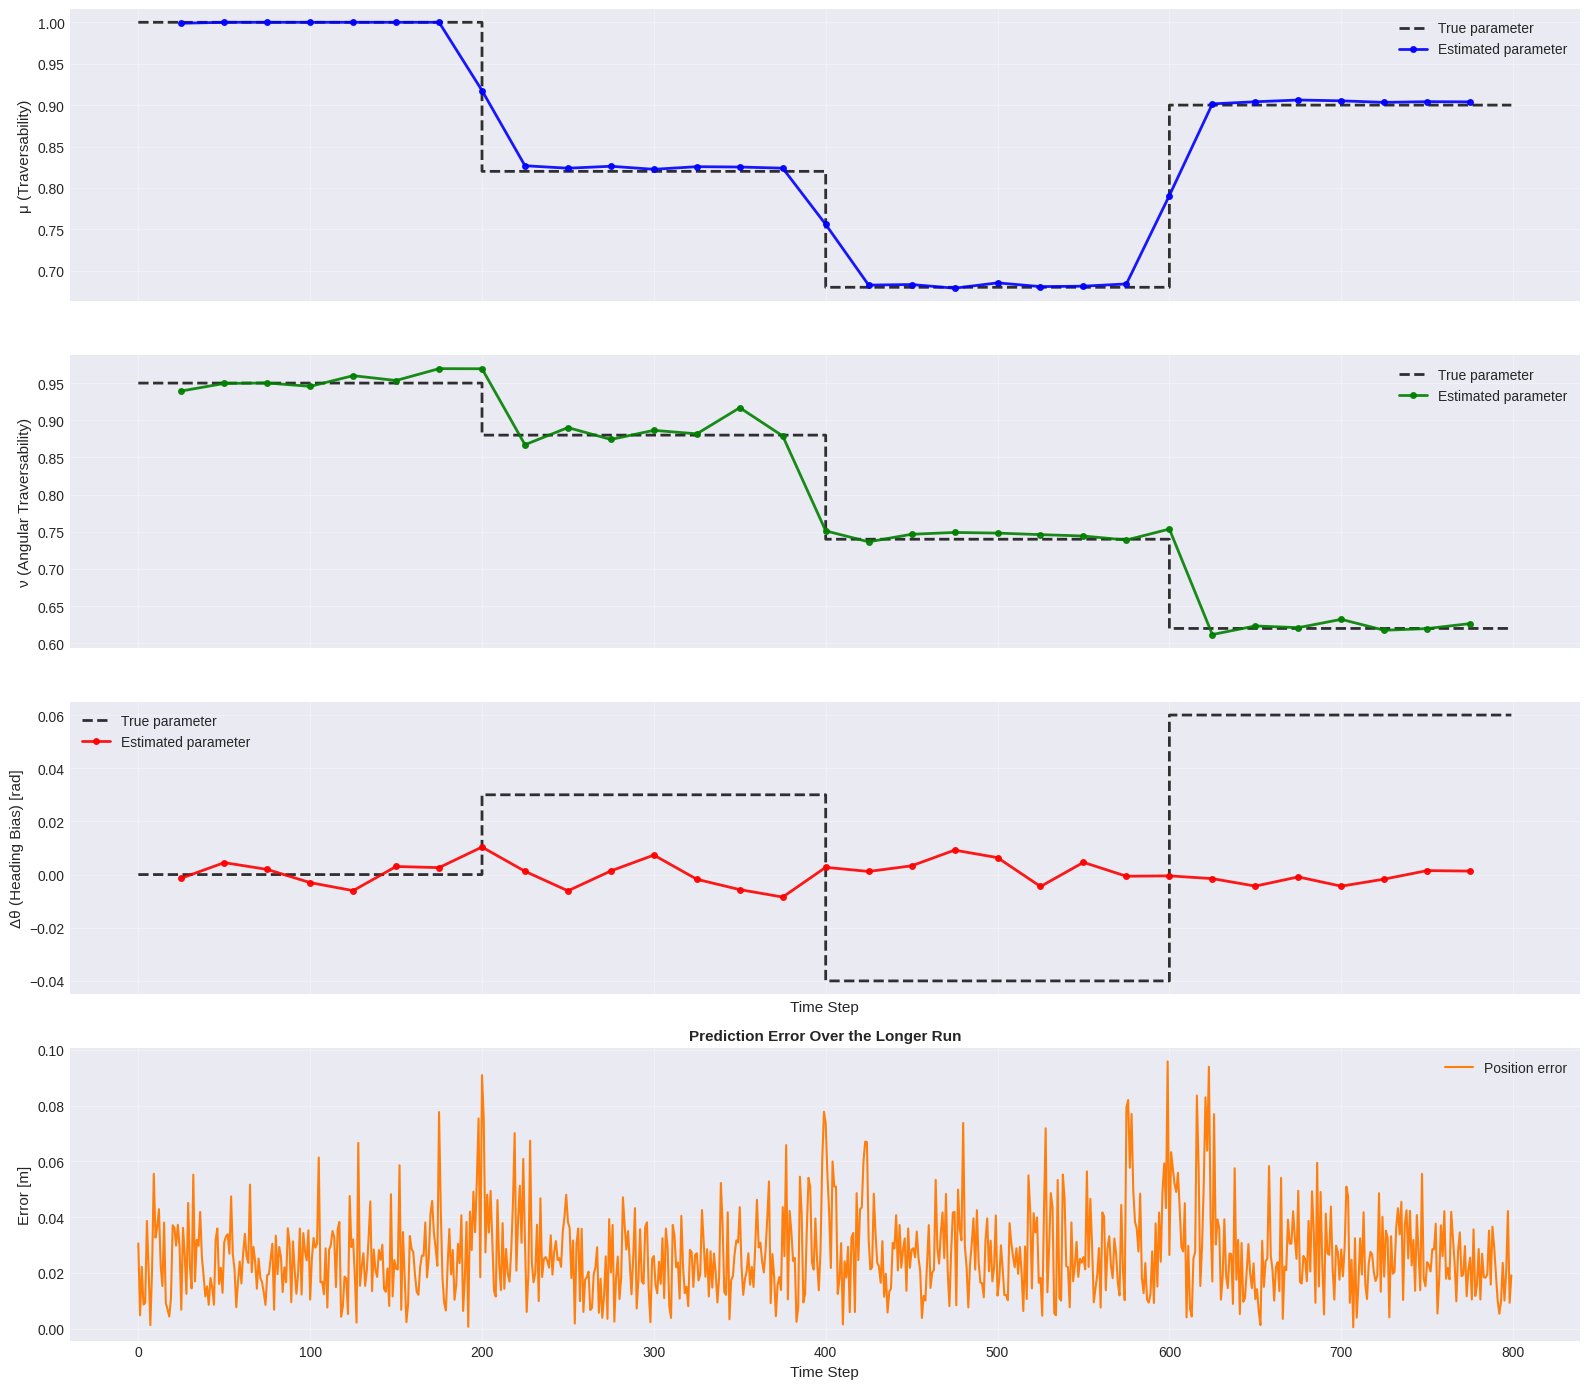

=== Time-Varying Parameter Tracking ===
baseline (0-200):
  true:      μ=1.000, ν=0.950, Δθ=0.000
  estimated: μ=1.000, ν=0.952, Δθ=0.000
  mean abs error: μ=0.000, ν=0.002, Δθ=0.000

soft soil (200-400):
  true:      μ=0.820, ν=0.880, Δθ=0.030
  estimated: μ=0.836, ν=0.896, Δθ=-0.000
  mean abs error: μ=0.016, ν=0.016, Δθ=0.030

loose ground (400-600):
  true:      μ=0.680, ν=0.740, Δθ=-0.040
  estimated: μ=0.692, ν=0.745, Δθ=0.003
  mean abs error: μ=0.012, ν=0.005, Δθ=0.043

asymmetric traction (600-800):
  true:      μ=0.900, ν=0.620, Δθ=0.060
  estimated: μ=0.890, ν=0.638, Δθ=-0.001
  mean abs error: μ=0.010, ν=0.018, Δθ=0.061

Overall mean absolute error:
  μ: 0.0118
  ν: 0.0139
  Δθ: 0.0354


In [28]:
# Generate a longer trajectory where traversability parameters change over time.
np.random.seed(7)

N_long = 800
N_horizon_tv = 50
dt_tv = 0.1
step_size_tv = N_horizon_tv // 2

# A longer control sequence with enough excitation to make the estimation meaningful.
U_long = np.zeros((N_long, 2))
U_long[:, 0] = 1.0
U_long[:200, 1] = 0.25
U_long[200:400, 1] = -0.15
U_long[400:600, 1] = 0.35
U_long[600:, 1] = -0.25

# Piecewise-varying ground truth parameters.
param_schedule = [
    (0, 200, np.array([1.00, 0.95, 0.00]), "baseline"),
    (200, 400, np.array([0.82, 0.88, 0.03]), "soft soil"),
    (400, 600, np.array([0.68, 0.74, -0.04]), "loose ground"),
    (600, 800, np.array([0.90, 0.62, 0.06]), "asymmetric traction"),
]

m_true_series = np.zeros((N_long, 3))
for start_idx, end_idx, params, _label in param_schedule:
    m_true_series[start_idx:end_idx] = params

rhe_tv_true = RecedingHorizonEstimator(dt=dt_tv, N=N_horizon_tv)
X_true_tv = np.zeros((N_long, 3))
X_true_tv[0] = np.array([0.0, 0.0, 0.0])
for i in range(N_long - 1):
    X_true_tv[i + 1] = rhe_tv_true.dynamics(X_true_tv[i], U_long[i], m_true_series[i])

Z_noisy_tv = X_true_tv + np.random.normal(0, 0.02, X_true_tv.shape)

rhe_tv = RecedingHorizonEstimator(dt=dt_tv, N=N_horizon_tv)
window_starts_tv = list(range(0, N_long - N_horizon_tv + 1, step_size_tv))
window_centers_tv = np.array(window_starts_tv) + N_horizon_tv // 2

X_predicted_tv = np.zeros((N_long, 3))
X_predicted_tv_counts = np.zeros(N_long)
m_estimates_tv = np.zeros((len(window_starts_tv), 3))
m_true_windows_tv = m_true_series[window_centers_tv]

for window_idx, window_start in enumerate(window_starts_tv):
    U_window = U_long[window_start : window_start + N_horizon_tv]
    Z_window = Z_noisy_tv[window_start : window_start + N_horizon_tv]

    X_est, m_est = rhe_tv.estimate(U_window, Z_window)

    window_end = window_start + N_horizon_tv
    X_predicted_tv[window_start:window_end] += X_est
    X_predicted_tv_counts[window_start:window_end] += 1.0
    m_estimates_tv[window_idx] = m_est

X_predicted_tv = X_predicted_tv / X_predicted_tv_counts[:, None]
position_error_tv = np.linalg.norm(X_predicted_tv[:, :2] - Z_noisy_tv[:, :2], axis=1)

fig, axes = plt.subplots(4, 1, figsize=(16, 14), sharex=True)
parameter_specs = [
    (0, "μ (Traversability)", "b", "mu"),
    (1, "ν (Angular Traversability)", "g", "nu"),
    (2, "Δθ (Heading Bias) [rad]", "r", "delta_theta"),
]

for ax, (param_idx, ylabel, color, _name) in zip(axes[:3], parameter_specs):
    ax.step(
        np.arange(N_long),
        m_true_series[:, param_idx],
        where="post",
        color="k",
        linestyle="--",
        linewidth=2,
        label="True parameter",
        alpha=0.8,
    )
    ax.plot(
        window_centers_tv,
        m_estimates_tv[:, param_idx],
        f"{color}-o",
        linewidth=2,
        markersize=4,
        label="Estimated parameter",
        alpha=0.9,
    )
    ax.set_ylabel(ylabel, fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best")

axes[2].set_xlabel("Time Step", fontsize=11)

axes[3].plot(
    position_error_tv, color="tab:orange", linewidth=1.5, label="Position error"
)
axes[3].set_xlabel("Time Step", fontsize=11)
axes[3].set_ylabel("Error [m]", fontsize=11)
axes[3].set_title(
    "Prediction Error Over the Longer Run", fontsize=11, fontweight="bold"
)
axes[3].grid(True, alpha=0.3)
axes[3].legend(loc="best")

plt.tight_layout()
plt.savefig(
    "/tmp/rhe_time_varying_parameter_tracking.png", dpi=150, bbox_inches="tight"
)
plt.show()

print("=== Time-Varying Parameter Tracking ===")
for start_idx, end_idx, params, label in param_schedule:
    mask = (window_centers_tv >= start_idx) & (window_centers_tv < end_idx)
    segment_estimate = m_estimates_tv[mask].mean(axis=0)
    segment_error = np.abs(segment_estimate - params)
    print(f"{label} ({start_idx}-{end_idx}):")
    print(f"  true:      μ={params[0]:.3f}, ν={params[1]:.3f}, Δθ={params[2]:.3f}")
    print(
        f"  estimated: μ={segment_estimate[0]:.3f}, ν={segment_estimate[1]:.3f}, Δθ={segment_estimate[2]:.3f}"
    )
    print(
        f"  mean abs error: μ={segment_error[0]:.3f}, ν={segment_error[1]:.3f}, Δθ={segment_error[2]:.3f}"
    )
    print()

print("Overall mean absolute error:")
print(f"  μ: {np.mean(np.abs(m_estimates_tv[:, 0] - m_true_windows_tv[:, 0])):.4f}")
print(f"  ν: {np.mean(np.abs(m_estimates_tv[:, 1] - m_true_windows_tv[:, 1])):.4f}")
print(f"  Δθ: {np.mean(np.abs(m_estimates_tv[:, 2] - m_true_windows_tv[:, 2])):.4f}")

## Test 4c: Sparse Angular Command Convergence

Visualize parameter estimation when the angular command varies over time but frequently drops to zero.

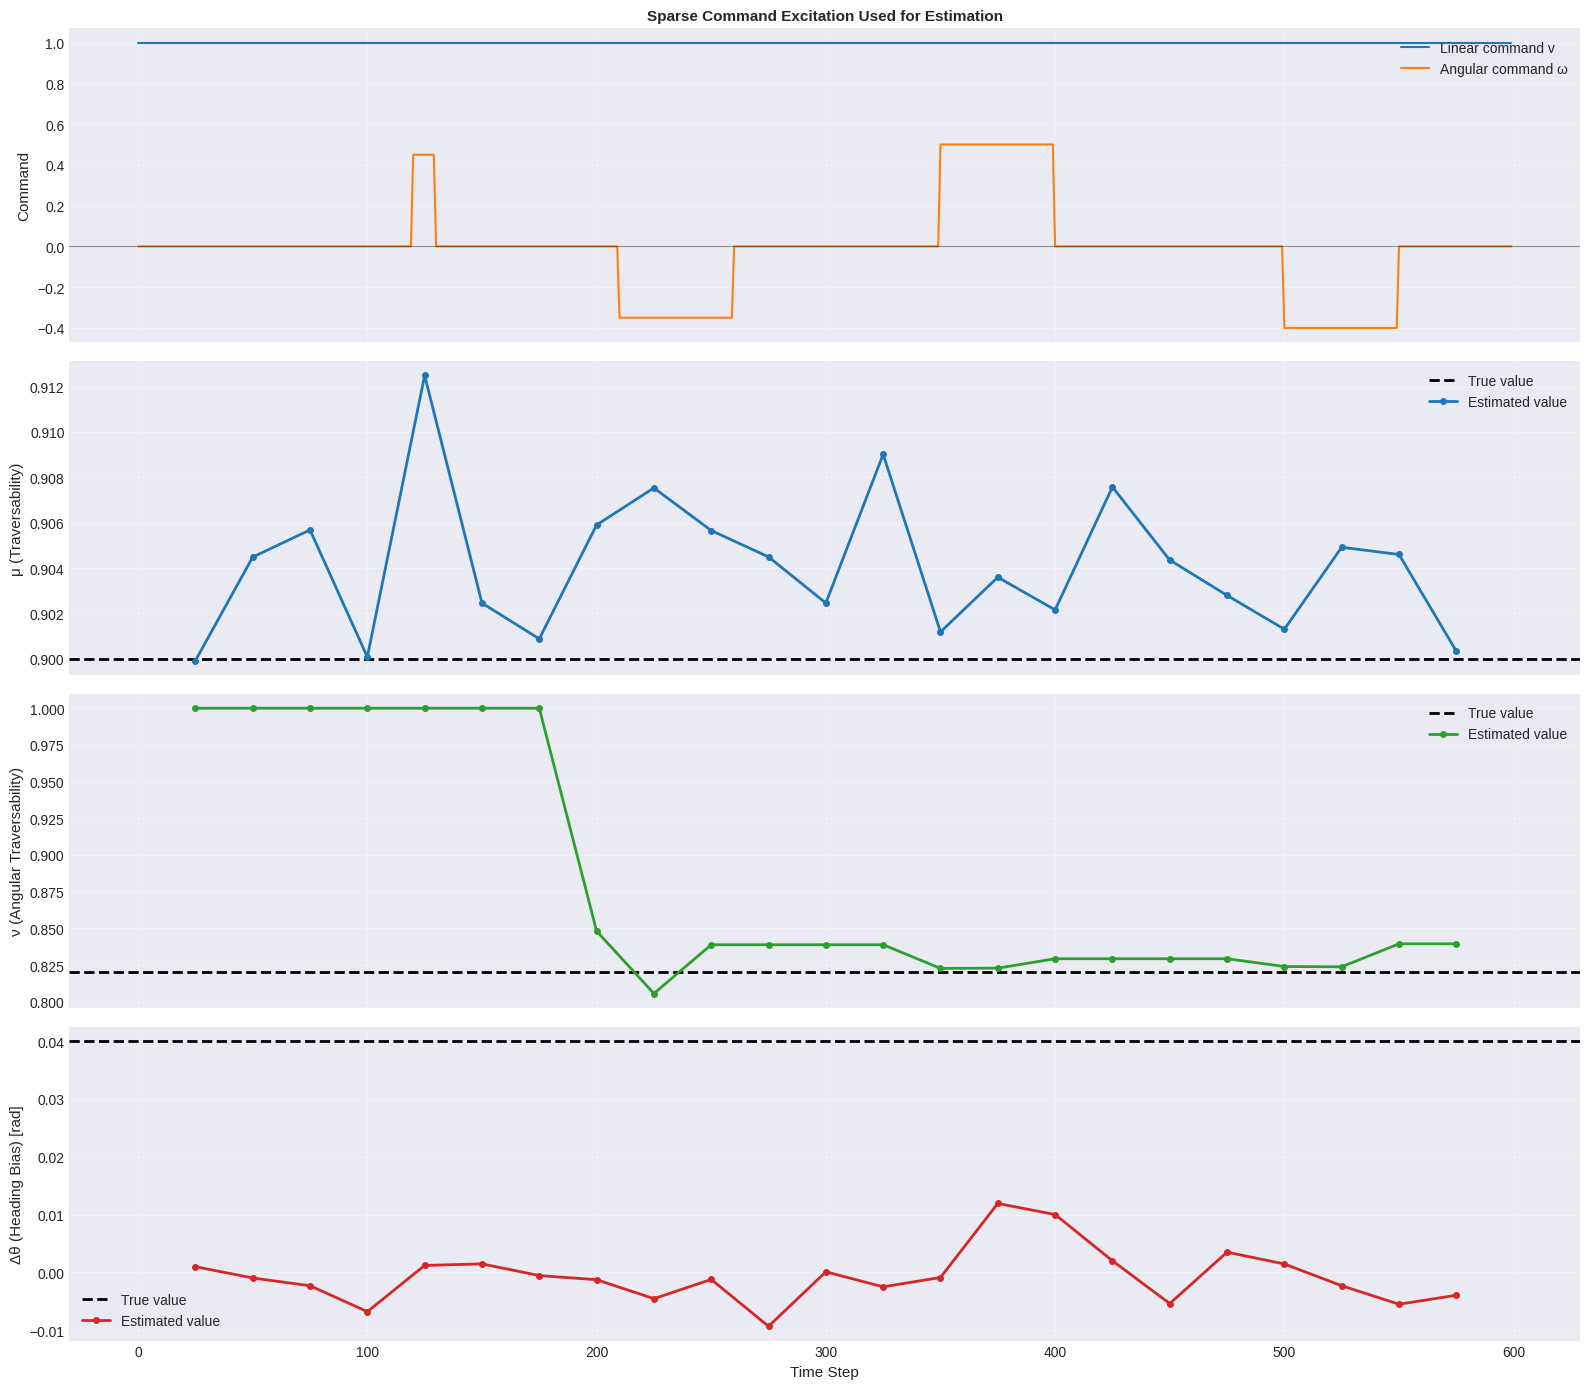

=== Sparse Command Convergence ===
True parameters: μ=0.900, ν=0.820, Δθ=0.040
Angular command zero ratio: 73.33%
Final estimates: μ=0.900, ν=0.839, Δθ=-0.004
Mean abs error: μ=0.0041
Mean abs error: ν=0.0638
Mean abs error: Δθ=0.0406


In [29]:
# Generate a longer trajectory where the angular command varies, but often drops to zero.
np.random.seed(21)

N_sparse = 600
N_horizon_sparse = 50
dt_sparse = 0.1
step_size_sparse = N_horizon_sparse // 2

U_sparse = np.zeros((N_sparse, 2))
U_sparse[:, 0] = 1.0

# Angular command with intermittent bursts and long zero intervals.
U_sparse[120:130, 1] = 0.45
U_sparse[210:260, 1] = -0.35
U_sparse[350:400, 1] = 0.50
U_sparse[500:550, 1] = -0.40

m_true_sparse = np.array([0.90, 0.82, 0.04])

rhe_sparse_true = RecedingHorizonEstimator(dt=dt_sparse, N=N_horizon_sparse)
X_true_sparse = np.zeros((N_sparse, 3))
X_true_sparse[0] = np.array([0.0, 0.0, 0.0])
for i in range(N_sparse - 1):
    X_true_sparse[i + 1] = rhe_sparse_true.dynamics(
        X_true_sparse[i], U_sparse[i], m_true_sparse
    )

Z_noisy_sparse = X_true_sparse + np.random.normal(0, 0.02, X_true_sparse.shape)

rhe_sparse = RecedingHorizonEstimator(dt=dt_sparse, N=N_horizon_sparse)
window_starts_sparse = list(range(0, N_sparse - N_horizon_sparse + 1, step_size_sparse))
window_centers_sparse = np.array(window_starts_sparse) + N_horizon_sparse // 2
m_estimates_sparse = np.zeros((len(window_starts_sparse), 3))

for window_idx, window_start in enumerate(window_starts_sparse):
    U_window = U_sparse[window_start : window_start + N_horizon_sparse]
    Z_window = Z_noisy_sparse[window_start : window_start + N_horizon_sparse]

    _, m_est = rhe_sparse.estimate(U_window, Z_window)
    m_estimates_sparse[window_idx] = m_est

fig, axes = plt.subplots(4, 1, figsize=(16, 14), sharex=True)

axes[0].plot(U_sparse[:, 0], color="tab:blue", linewidth=1.5, label="Linear command v")
axes[0].plot(
    U_sparse[:, 1], color="tab:orange", linewidth=1.5, label="Angular command ω"
)
axes[0].axhline(0.0, color="k", linewidth=0.8, alpha=0.4)
axes[0].set_ylabel("Command", fontsize=11)
axes[0].set_title(
    "Sparse Command Excitation Used for Estimation", fontsize=11, fontweight="bold"
)
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc="upper right")

parameter_labels = [
    (0, "μ (Traversability)", "tab:blue"),
    (1, "ν (Angular Traversability)", "tab:green"),
    (2, "Δθ (Heading Bias) [rad]", "tab:red"),
]

for ax, (param_idx, ylabel, color) in zip(axes[1:], parameter_labels):
    ax.axhline(
        m_true_sparse[param_idx],
        color="k",
        linestyle="--",
        linewidth=2,
        label="True value",
    )
    ax.plot(
        window_centers_sparse,
        m_estimates_sparse[:, param_idx],
        color=color,
        marker="o",
        linewidth=2,
        markersize=4,
        label="Estimated value",
    )
    ax.set_ylabel(ylabel, fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best")

axes[-1].set_xlabel("Time Step", fontsize=11)

plt.tight_layout()
plt.savefig("/tmp/rhe_sparse_command_convergence.png", dpi=150, bbox_inches="tight")
plt.show()

print("=== Sparse Command Convergence ===")
print(
    f"True parameters: μ={m_true_sparse[0]:.3f}, ν={m_true_sparse[1]:.3f}, Δθ={m_true_sparse[2]:.3f}"
)
print(f"Angular command zero ratio: {np.mean(np.isclose(U_sparse[:, 1], 0.0)):.2%}")
print(
    f"Final estimates: μ={m_estimates_sparse[-1, 0]:.3f}, ν={m_estimates_sparse[-1, 1]:.3f}, Δθ={m_estimates_sparse[-1, 2]:.3f}"
)
print(
    f"Mean abs error: μ={np.mean(np.abs(m_estimates_sparse[:, 0] - m_true_sparse[0])):.4f}"
)
print(
    f"Mean abs error: ν={np.mean(np.abs(m_estimates_sparse[:, 1] - m_true_sparse[1])):.4f}"
)
print(
    f"Mean abs error: Δθ={np.mean(np.abs(m_estimates_sparse[:, 2] - m_true_sparse[2])):.4f}"
)

## Test 4d: Sparse Angular Command With Varying Traversability

Use the same sparse angular command profile, but let the true traversability coefficients drift across the run.

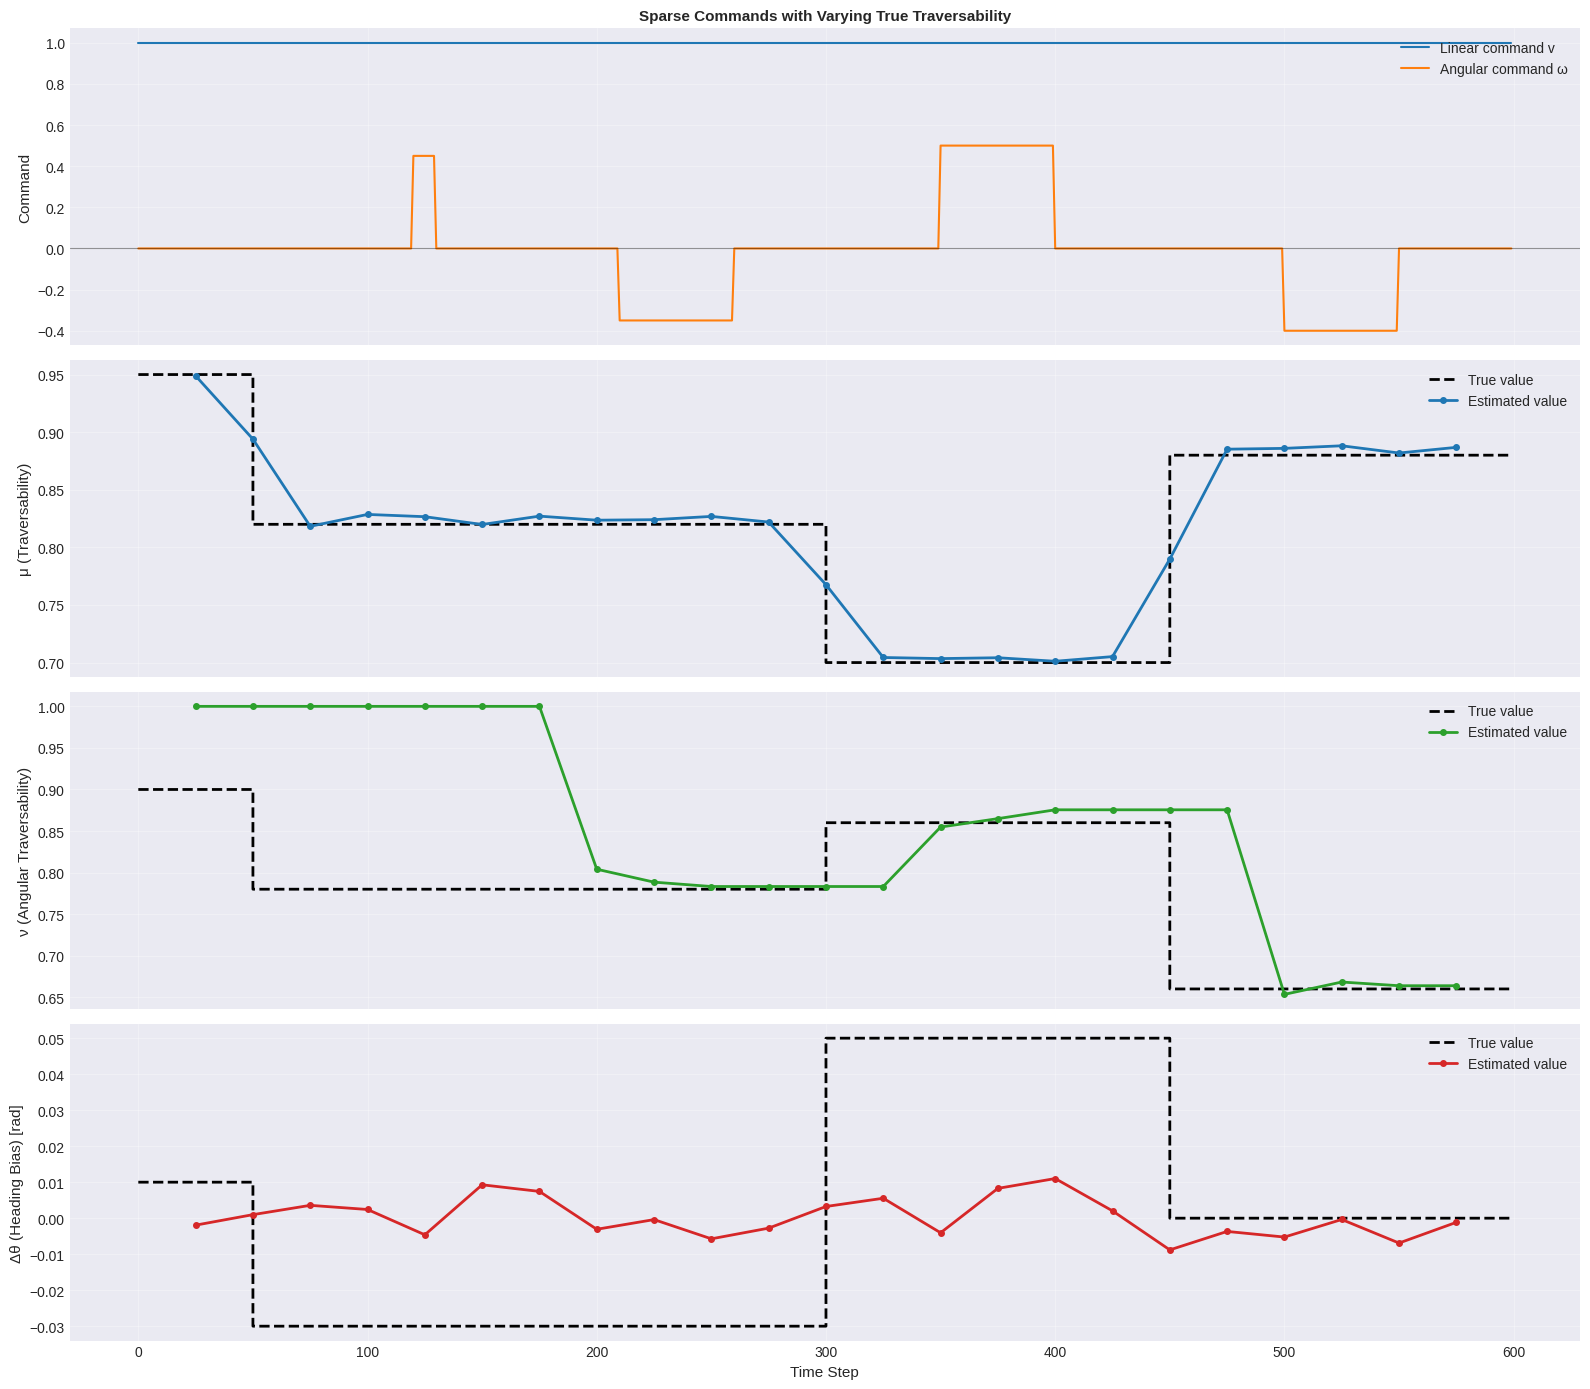

=== Sparse Command With Varying Traversability ===
Angular command zero ratio: 73.33%
Segment 0-150:
  true:      μ=0.846, ν=0.804, Δθ=-0.022
  estimated: μ=0.863, ν=1.000, Δθ=0.000
  mean abs error: μ=0.017, ν=0.196, Δθ=0.022

Segment 150-300:
  true:      μ=0.820, ν=0.780, Δθ=-0.030
  estimated: μ=0.824, ν=0.860, Δθ=0.001
  mean abs error: μ=0.004, ν=0.080, Δθ=0.031

Segment 300-450:
  true:      μ=0.700, ν=0.860, Δθ=0.050
  estimated: μ=0.714, ν=0.840, Δθ=0.004
  mean abs error: μ=0.014, ν=0.020, Δθ=0.046

Segment 450-600:
  true:      μ=0.880, ν=0.660, Δθ=0.000
  estimated: μ=0.870, ν=0.733, Δθ=-0.004
  mean abs error: μ=0.010, ν=0.073, Δθ=0.004

Overall mean absolute error:
  μ: 0.0139
  ν: 0.0916
  Δθ: 0.0269


In [30]:
# Reuse the sparse angular command profile, but let the true traversability coefficients change over time.
np.random.seed(22)

m_true_sparse_series = np.zeros((N_sparse, 3))
m_true_sparse_series[:50] = np.array([0.95, 0.90, 0.01])
m_true_sparse_series[50:300] = np.array([0.82, 0.78, -0.03])
m_true_sparse_series[300:450] = np.array([0.70, 0.86, 0.05])
m_true_sparse_series[450:] = np.array([0.88, 0.66, 0.00])

rhe_sparse_varying_true = RecedingHorizonEstimator(dt=dt_sparse, N=N_horizon_sparse)
X_true_sparse_varying = np.zeros((N_sparse, 3))
X_true_sparse_varying[0] = np.array([0.0, 0.0, 0.0])
for i in range(N_sparse - 1):
    X_true_sparse_varying[i + 1] = rhe_sparse_varying_true.dynamics(
        X_true_sparse_varying[i], U_sparse[i], m_true_sparse_series[i]
    )

Z_noisy_sparse_varying = X_true_sparse_varying + np.random.normal(
    0, 0.02, X_true_sparse_varying.shape
)

rhe_sparse_varying = RecedingHorizonEstimator(dt=dt_sparse, N=N_horizon_sparse)
m_estimates_sparse_varying = np.zeros((len(window_starts_sparse), 3))
m_true_windows_sparse_varying = m_true_sparse_series[window_centers_sparse]

for window_idx, window_start in enumerate(window_starts_sparse):
    U_window = U_sparse[window_start : window_start + N_horizon_sparse]
    Z_window = Z_noisy_sparse_varying[window_start : window_start + N_horizon_sparse]

    _, m_est = rhe_sparse_varying.estimate(U_window, Z_window)
    m_estimates_sparse_varying[window_idx] = m_est

fig, axes = plt.subplots(4, 1, figsize=(16, 14), sharex=True)

axes[0].plot(U_sparse[:, 0], color="tab:blue", linewidth=1.5, label="Linear command v")
axes[0].plot(
    U_sparse[:, 1], color="tab:orange", linewidth=1.5, label="Angular command ω"
)
axes[0].axhline(0.0, color="k", linewidth=0.8, alpha=0.4)
axes[0].set_ylabel("Command", fontsize=11)
axes[0].set_title(
    "Sparse Commands with Varying True Traversability", fontsize=11, fontweight="bold"
)
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc="upper right")

parameter_labels = [
    (0, "μ (Traversability)", "tab:blue"),
    (1, "ν (Angular Traversability)", "tab:green"),
    (2, "Δθ (Heading Bias) [rad]", "tab:red"),
]

for ax, (param_idx, ylabel, color) in zip(axes[1:], parameter_labels):
    ax.step(
        np.arange(N_sparse),
        m_true_sparse_series[:, param_idx],
        where="post",
        color="k",
        linestyle="--",
        linewidth=2,
        label="True value",
    )
    ax.plot(
        window_centers_sparse,
        m_estimates_sparse_varying[:, param_idx],
        color=color,
        marker="o",
        linewidth=2,
        markersize=4,
        label="Estimated value",
    )
    ax.set_ylabel(ylabel, fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best")

axes[-1].set_xlabel("Time Step", fontsize=11)

plt.tight_layout()
plt.savefig(
    "/tmp/rhe_sparse_command_varying_parameters.png", dpi=150, bbox_inches="tight"
)
plt.show()

print("=== Sparse Command With Varying Traversability ===")
print(f"Angular command zero ratio: {np.mean(np.isclose(U_sparse[:, 1], 0.0)):.2%}")
for start_idx, end_idx in [(0, 150), (150, 300), (300, 450), (450, 600)]:
    mask = (window_centers_sparse >= start_idx) & (window_centers_sparse < end_idx)
    segment_estimate = m_estimates_sparse_varying[mask].mean(axis=0)
    segment_true = m_true_sparse_series[window_centers_sparse][mask].mean(axis=0)
    segment_error = np.abs(segment_estimate - segment_true)
    print(f"Segment {start_idx}-{end_idx}:")
    print(
        f"  true:      μ={segment_true[0]:.3f}, ν={segment_true[1]:.3f}, Δθ={segment_true[2]:.3f}"
    )
    print(
        f"  estimated: μ={segment_estimate[0]:.3f}, ν={segment_estimate[1]:.3f}, Δθ={segment_estimate[2]:.3f}"
    )
    print(
        f"  mean abs error: μ={segment_error[0]:.3f}, ν={segment_error[1]:.3f}, Δθ={segment_error[2]:.3f}"
    )
    print()

print("Overall mean absolute error:")
print(
    f"  μ: {np.mean(np.abs(m_estimates_sparse_varying[:, 0] - m_true_windows_sparse_varying[:, 0])):.4f}"
)
print(
    f"  ν: {np.mean(np.abs(m_estimates_sparse_varying[:, 1] - m_true_windows_sparse_varying[:, 1])):.4f}"
)
print(
    f"  Δθ: {np.mean(np.abs(m_estimates_sparse_varying[:, 2] - m_true_windows_sparse_varying[:, 2])):.4f}"
)

## Test 5: Horizon Window Analysis

Analyze the effect of horizon length (N) on estimation quality.

In [31]:
# Test different horizon lengths
horizon_lengths = [20, 30, 50, 75, 100]
results = {}

# Use first 200 steps for this test
test_steps = 200
U_test = U_total[:test_steps]
Z_test = Z_noisy[:test_steps]

print("=== Horizon Length Analysis ===")
for N_horizon_test in horizon_lengths:
    if N_horizon_test >= test_steps:
        continue

    rhe_test = RecedingHorizonEstimator(dt=dt, N=N_horizon_test)
    U_window = U_test[:N_horizon_test]
    Z_window = Z_test[:N_horizon_test]

    try:
        X_est, m_est = rhe_test.estimate(U_window, Z_window)

        # Calculate error
        position_error_test = np.sqrt(
            (X_est[:, 0] - Z_window[:, 0]) ** 2 + (X_est[:, 1] - Z_window[:, 1]) ** 2
        )
        results[N_horizon_test] = {
            "m_est": m_est,
            "mean_pos_error": np.mean(position_error_test),
            "max_pos_error": np.max(position_error_test),
        }
        print(
            f"N={N_horizon_test}: μ={m_est[0]:.3f}, ν={m_est[1]:.3f}, Δθ={m_est[2]:.4f}, mean error={results[N_horizon_test]['mean_pos_error']:.4f} m"
        )
    except Exception as e:
        print(f"N={N_horizon_test}: Failed - {e}")

=== Horizon Length Analysis ===
N=20: μ=0.796, ν=0.872, Δθ=0.0318, mean error=0.0213 m
N=30: μ=0.799, ν=0.858, Δθ=0.0371, mean error=0.0219 m
N=50: μ=0.799, ν=0.850, Δθ=0.0457, mean error=0.0223 m
N=75: μ=0.800, ν=0.851, Δθ=0.0510, mean error=0.0223 m
N=100: μ=0.799, ν=0.850, Δθ=0.0519, mean error=0.0227 m


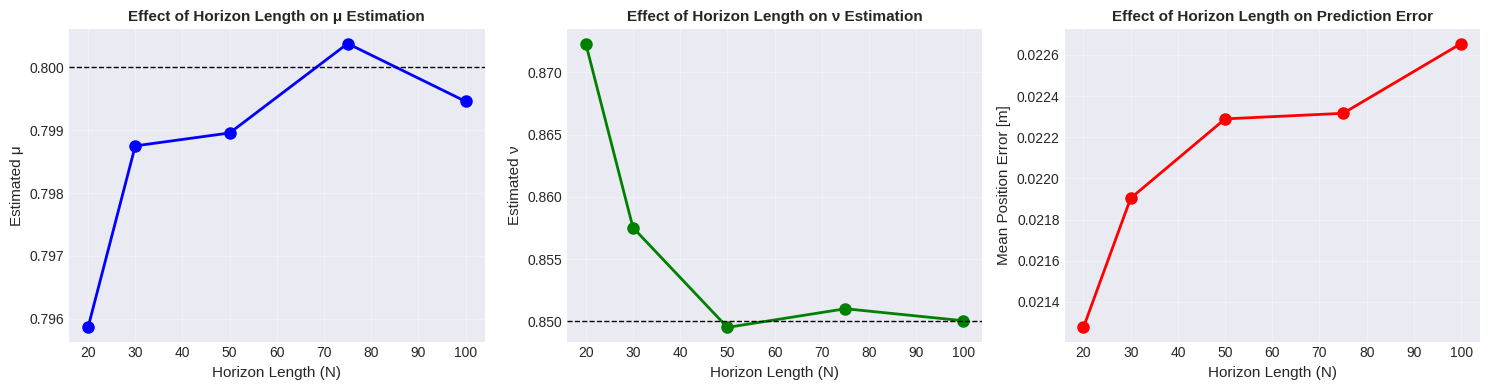

In [32]:
# Plot horizon length effects
if "results" not in locals() or not results:
    print("Run the previous horizon-analysis cell first to populate 'results'.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    horizons = sorted(results.keys())
    mu_vals = [results[h]["m_est"][0] for h in horizons]
    nu_vals = [results[h]["m_est"][1] for h in horizons]
    errors = [results[h]["mean_pos_error"] for h in horizons]

    axes[0].plot(horizons, mu_vals, "b-o", linewidth=2, markersize=8)
    axes[0].axhline(mu_true, color="k", linestyle="--", linewidth=1)
    axes[0].set_xlabel("Horizon Length (N)", fontsize=11)
    axes[0].set_ylabel("Estimated μ", fontsize=11)
    axes[0].set_title(
        "Effect of Horizon Length on μ Estimation", fontsize=11, fontweight="bold"
    )
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(horizons, nu_vals, "g-o", linewidth=2, markersize=8)
    axes[1].axhline(nu_true, color="k", linestyle="--", linewidth=1)
    axes[1].set_xlabel("Horizon Length (N)", fontsize=11)
    axes[1].set_ylabel("Estimated ν", fontsize=11)
    axes[1].set_title(
        "Effect of Horizon Length on ν Estimation", fontsize=11, fontweight="bold"
    )
    axes[1].grid(True, alpha=0.3)

    axes[2].plot(horizons, errors, "r-o", linewidth=2, markersize=8)
    axes[2].set_xlabel("Horizon Length (N)", fontsize=11)
    axes[2].set_ylabel("Mean Position Error [m]", fontsize=11)
    axes[2].set_title(
        "Effect of Horizon Length on Prediction Error", fontsize=11, fontweight="bold"
    )
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig("/tmp/rhe_horizon_analysis.png", dpi=150, bbox_inches="tight")
    plt.show()

## Test 6: Covariance Matrix Effects

Analyze how different covariance weights (P_x, P_m, P_w) affect parameter estimation.

In [33]:
# Test effect of different covariance matrices
N_test = 50
U_test_cov = U_total[:N_test]
Z_test_cov = Z_noisy[:N_test]

covariance_configs = [
    (
        np.diag([10.0, 10.0, 10.0]),
        np.diag([1.0, 1.0, 1.0]),
        np.diag([1.0, 1.0, 1.0]),
        "Default (P_x=10, P_m=1, Pw=1)",
    ),
    (
        np.diag([1.0, 1.0, 1.0]),
        np.diag([1.0, 1.0, 1.0]),
        np.diag([1.0, 1.0, 1.0]),
        "Equal weights",
    ),
    (
        np.diag([100.0, 100.0, 100.0]),
        np.diag([1.0, 1.0, 1.0]),
        np.diag([1.0, 1.0, 1.0]),
        "High state prior",
    ),
    (
        np.diag([10.0, 10.0, 10.0]),
        np.diag([10.0, 10.0, 10.0]),
        np.diag([1.0, 1.0, 1.0]),
        "High parameter weight",
    ),
    (
        np.diag([1.0, 1.0, 1.0]),
        np.diag([1.0, 1.0, 1.0]),
        np.diag([10.0, 10.0, 10.0]),
        "High ground truth weight",
    ),
    (
        np.diag([10.0, 10.0, 10.0]),
        np.diag([1.0, 1.0, 1.0]),
        np.diag([10.0, 10.0, 10.0]),
        "High state and ground truth weight",
    ),
]

cov_results = []
print("=== Covariance Configuration Analysis ===")

for P_x, P_m, P_w, label in covariance_configs:
    rhe_cov = RecedingHorizonEstimator(dt=dt, N=N_test, P_x=P_x, P_m=P_m, P_w=P_w)

    try:
        X_est, m_est = rhe_cov.estimate(U_test_cov, Z_test_cov)
        position_error = np.sqrt(
            (X_est[:, 0] - Z_test_cov[:, 0]) ** 2
            + (X_est[:, 1] - Z_test_cov[:, 1]) ** 2
        )

        cov_results.append({
            "label": label,
            "P_x_diag": np.diag(P_x),
            "m_est": m_est,
            "mean_error": np.mean(position_error),
            "X_est": X_est,
        })
        print(f"{label}")
        print(f"  Estimated: μ={m_est[0]:.3f}, ν={m_est[1]:.3f}, Δθ={m_est[2]:.4f}")
        print(f"  Mean error: {np.mean(position_error):.4f} m")
    except Exception as e:
        print(f"{label}: Failed - {e}")

=== Covariance Configuration Analysis ===
Default (P_x=10, P_m=1, Pw=1)
  Estimated: μ=0.786, ν=0.641, Δθ=0.0128
  Mean error: 0.0639 m
Equal weights
  Estimated: μ=0.799, ν=0.829, Δθ=0.0365
  Mean error: 0.0242 m
High state prior
  Estimated: μ=0.760, ν=0.170, Δθ=0.0581
  Mean error: 0.2203 m
High parameter weight
  Estimated: μ=0.805, ν=0.766, Δθ=-0.0041
  Mean error: 0.0643 m
High ground truth weight
  Estimated: μ=0.799, ν=0.850, Δθ=0.0457
  Mean error: 0.0223 m
High state and ground truth weight
  Estimated: μ=0.797, ν=0.816, Δθ=0.0381
  Mean error: 0.0243 m


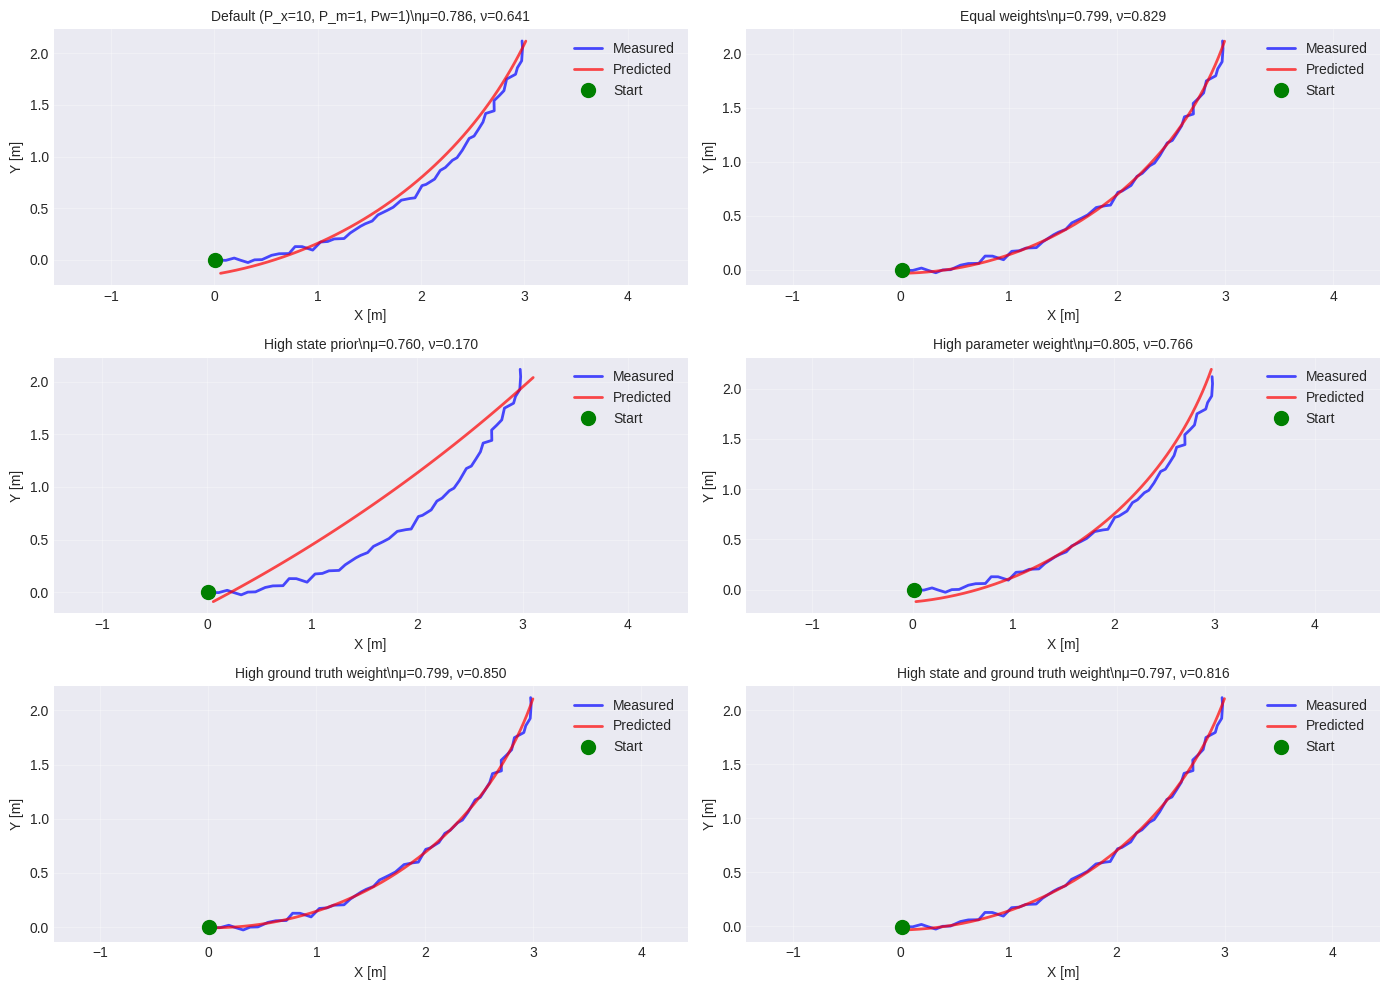

In [34]:
# Visualize covariance effects
if "cov_results" not in locals() or not cov_results:
    print("Run the previous covariance-analysis cell first to populate 'cov_results'.")
else:
    fig, axes = plt.subplots(3, 2, figsize=(14, 10))

    for idx, result in enumerate(cov_results):
        ax = axes[idx // 2, idx % 2]
        label = result["label"]
        X_est = result["X_est"]

        ax.plot(
            Z_test_cov[:, 0],
            Z_test_cov[:, 1],
            "b-",
            linewidth=2,
            label="Measured",
            alpha=0.7,
        )
        ax.plot(
            X_est[:, 0], X_est[:, 1], "r", linewidth=2, label="Predicted", alpha=0.7
        )
        ax.plot(Z_test_cov[0, 0], Z_test_cov[0, 1], "go", markersize=10, label="Start")

        ax.set_xlabel("X [m]")
        ax.set_ylabel("Y [m]")
        ax.set_title(
            f"{label}\\nμ={result['m_est'][0]:.3f}, ν={result['m_est'][1]:.3f}",
            fontsize=10,
        )
        ax.legend()
        ax.grid(True, alpha=0.3)
        ax.axis("equal")

    plt.tight_layout()
    plt.savefig("/tmp/rhe_covariance_analysis.png", dpi=150, bbox_inches="tight")
    plt.show()

## Test 8: Reset Functionality

Verify that the reset() method properly clears internal state.

In [35]:
# Test reset functionality
print("=== Reset Functionality Test ===")

rhe_reset = RecedingHorizonEstimator(dt=0.1, N=50)

# First estimation
U_test1 = U_total[:50]
Z_test1 = Z_noisy[:50]
X_est1, m_est1 = rhe_reset.estimate(U_test1, Z_test1)
print(f"First estimation: μ={m_est1[0]:.3f}, ν={m_est1[1]:.3f}")
print(
    f"Internal state after first: prev_x={rhe_reset.prev_x}, prev_m={rhe_reset.prev_m}"
)

# Second estimation (should use state from first)
U_test2 = U_total[50:100]
Z_test2 = Z_noisy[50:100]
X_est2, m_est2 = rhe_reset.estimate(U_test2, Z_test2)
print(f"\nSecond estimation: μ={m_est2[0]:.3f}, ν={m_est2[1]:.3f}")
print(
    f"Internal state after second: prev_x={rhe_reset.prev_x}, prev_m={rhe_reset.prev_m}"
)

# Reset and verify
rhe_reset.reset()
print(f"\nAfter reset: prev_x={rhe_reset.prev_x}, prev_m={rhe_reset.prev_m}")

# Third estimation after reset (should give different result than using state from first)
X_est3, m_est3 = rhe_reset.estimate(U_test1, Z_test1)
print(f"\nThird estimation (after reset): μ={m_est3[0]:.3f}, ν={m_est3[1]:.3f}")
print(
    f"Difference from first: μ_diff={abs(m_est1[0] - m_est3[0]):.6f}, ν_diff={abs(m_est1[1] - m_est3[1]):.6f}"
)

=== Reset Functionality Test ===
First estimation: μ=0.799, ν=0.850
Internal state after first: prev_x=[ 0.08301108 -0.00540264  0.02823649], prev_m=[0.79895644 0.84951408 0.04572591]

Second estimation: μ=0.803, ν=0.870
Internal state after second: prev_x=[3.03358149 2.24458781 1.28389297], prev_m=[0.80338596 0.86976309 0.0645255 ]

After reset: prev_x=None, prev_m=None

Third estimation (after reset): μ=0.799, ν=0.850
Difference from first: μ_diff=0.000000, ν_diff=0.000000
